## Step 1: Install and imports

In [1]:
!pip install -U ultralytics grad-cam --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 552.7 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.7 MB/s eta 0:00:00


In [2]:
import json, copy
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score,
                             recall_score, f1_score)
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Step 2: Shared helpers

In [3]:
"""Shared helpers used by notebooks 02, 03 and 04.
"""
import os
import time
import random
import shutil

import numpy as np
import pandas as pd
import cv2

IMG_SIZE = 224
MODALITY_PIXEL = {0: 0, 1: 85, 2: 170, 3: 255}   # CTA, MRA, MRI T1post, MRI T2
MODALITY_NAMES = {0: "CTA", 1: "MRA", 2: "MRI T1post", 3: "MRI T2"}

SPLIT_NAMES = ["70_15_15", "80_10_10", "85_7dot5_7dot5"]
MAIN_SPLIT = "70_15_15"       # model comparison split (largest test set); other splits are ablations in notebook 03

# Colour jitter is disabled on purpose: the images are grayscale-derived and the
# third channel is a constant that encodes the modality, so hue/saturation/value
# changes would only corrupt that signal.
YOLO_COMMON = dict(epochs=50, imgsz=IMG_SIZE, batch=32, patience=15, seed=42,
                   hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, plots=False, exist_ok=True)


# --------------------------------------------------------------------------
# Locating files produced by notebook 01 / 02 (Kaggle nests outputs unpredictably)
# --------------------------------------------------------------------------
def find_file(name, base="/kaggle/input", max_depth=5,
              skip=("rsna-intracranial-aneurysm-detection",
                    "rsna-2025-intracranial-aneurysm-png-224x224")):
    """Walk `base` (bounded depth, skipping the huge raw datasets) and return the shortest match."""
    hits = []
    for root, dirs, files in os.walk(base):
        depth = root[len(base):].count(os.sep)
        dirs[:] = [d for d in dirs if d not in skip] if depth < max_depth else []
        if name in files:
            hits.append(os.path.join(root, name))
    return sorted(hits, key=len)[0] if hits else None


def find_data_root():
    path = find_file("final_df_v2.csv")
    assert path is not None, ("final_df_v2.csv not found. Add the output of notebook 01 "
                              "(Add Input -> Your Work -> Notebook output).")
    return os.path.dirname(path)


def load_split(split_name, data_root):
    """Read split_<name>.csv and attach absolute image paths (image_path in the CSV is relative)."""
    df = pd.read_csv(os.path.join(data_root, f"split_{split_name}.csv"))
    df["abs_path"] = data_root + "/" + df["image_path"]
    return df


# --------------------------------------------------------------------------
# Image construction
# --------------------------------------------------------------------------
def make_modality_image(gray, modality_code):
    """Stack [gray, gray, constant-modality-channel]."""
    h, w = gray.shape
    mod = np.full((h, w), MODALITY_PIXEL.get(int(modality_code), 128), dtype=np.uint8)
    return np.stack([gray, gray, mod], axis=-1)


def make_plain_image(gray):
    return np.stack([gray, gray, gray], axis=-1)


def transform_image_and_boxes(gray, boxes, kind, angle=0.0):
    """Apply orig / flip / rot to a grayscale image and its boxes.

    boxes: list of (xc, yc, w, h) in normalised coordinates.
    Returns (image, boxes). Boxes whose centre leaves the image after rotation are dropped.
    """
    if kind == "orig":
        return gray, list(boxes)
    if kind == "flip":
        return cv2.flip(gray, 1), [(1.0 - x, y, w, h) for x, y, w, h in boxes]
    if kind == "rot":
        h_img, w_img = gray.shape
        M = cv2.getRotationMatrix2D((w_img / 2, h_img / 2), angle, 1.0)
        rot = cv2.warpAffine(gray, M, (w_img, h_img), borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        out = []
        for x, y, w, h in boxes:
            px, py = x * w_img, y * h_img
            nx = (M[0, 0] * px + M[0, 1] * py + M[0, 2]) / w_img
            ny = (M[1, 0] * px + M[1, 1] * py + M[1, 2]) / h_img
            if 0.0 <= nx <= 1.0 and 0.0 <= ny <= 1.0:
                out.append((nx, ny, w, h))
        return rot, out
    raise ValueError(kind)


def image_table(split_df):
    """Collapse the box-level table to one row per image with its list of boxes."""
    rows = []
    for path, g in split_df.groupby("abs_path", sort=False):
        first = g.iloc[0]
        boxes = [(r.x_center, r.y_center, r.box_w, r.box_h) for r in g.itertuples()
                 if pd.notna(r.x_center)]
        rows.append(dict(abs_path=path, SeriesInstanceUID=first["SeriesInstanceUID"],
                         Modality=first["Modality"], modality_code=int(first["modality_code"]),
                         label=int(len(boxes) > 0), boxes=boxes, split=first["split"]))
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------
# YOLO dataset export
# --------------------------------------------------------------------------
def _write_label(path, boxes):
    with open(path, "w") as f:
        f.write("\n".join(f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for x, y, w, h in boxes))


def _link_or_copy(src, dst):
    try:
        os.link(src, dst)          # hard link: no extra disk space for oversampled duplicates
    except OSError:
        shutil.copy(src, dst)


def build_yolo_dataset(split_df, root, modality_aware=True, balance=True,
                       rot_deg=15, use_flip=True, seed=42):
    """Export one split to YOLO format.

    train: orig (+ flip) (+ rotation by +-rot_deg) variants of every image, all boxes of an
           image kept together; optional modality oversampling with hard links.
    val/test: original images only.
    Returns (yaml_path, stats_dict).
    """
    rng = random.Random(seed)
    if os.path.exists(root):
        shutil.rmtree(root)
    img_tab = image_table(split_df)

    def render(gray, code):
        return make_modality_image(gray, code) if modality_aware else make_plain_image(gray)

    stats, file_modality = {}, {}
    for part in ["train", "val", "test"]:
        os.makedirs(f"{root}/images/{part}", exist_ok=True)
        os.makedirs(f"{root}/labels/{part}", exist_ok=True)
        sub = img_tab[img_tab["split"] == part].reset_index(drop=True)
        n_files = 0
        for k, r in sub.iterrows():
            gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
            if gray is None:
                continue
            kinds = ["orig"]
            if part == "train":
                if use_flip:
                    kinds.append("flip")
                if rot_deg and rot_deg > 0:
                    kinds.append("rot")
            angle = rng.choice([-rot_deg, rot_deg]) if (part == "train" and rot_deg) else 0
            for kind in kinds:
                img_t, boxes_t = transform_image_and_boxes(gray, r["boxes"], kind, angle)
                if r["label"] == 1 and len(boxes_t) == 0:
                    continue                       # rotation pushed every box out of the frame
                base = f"{r['SeriesInstanceUID']}_{k}_{kind}"
                cv2.imwrite(f"{root}/images/{part}/{base}.png", render(img_t, r["modality_code"]))
                _write_label(f"{root}/labels/{part}/{base}.txt", boxes_t)
                file_modality[(part, base)] = r["Modality"]
                n_files += 1
        stats[part] = dict(images=n_files,
                           positive_images=int(sub["label"].sum()) if part != "train" else None,
                           boxes=int(sub["boxes"].apply(len).sum()) if part != "train" else None,
                           series=int(sub["SeriesInstanceUID"].nunique()))

    if balance:
        by_mod = {}
        for (part, base), mod in file_modality.items():
            if part == "train":
                by_mod.setdefault(mod, []).append(base)
        target = max(len(v) for v in by_mod.values())
        for mod, bases in by_mod.items():
            extra = rng.choices(bases, k=target - len(bases)) if len(bases) < target else []
            for i, base in enumerate(extra):
                _link_or_copy(f"{root}/images/train/{base}.png", f"{root}/images/train/{base}_dup{i}.png")
                _link_or_copy(f"{root}/labels/train/{base}.txt", f"{root}/labels/train/{base}_dup{i}.txt")
        stats["train_balanced_per_modality"] = target

    stats["train"]["images"] = len(os.listdir(f"{root}/images/train"))
    stats["train"]["positive_images"] = int(sum(
        os.path.getsize(f"{root}/labels/train/{f}") > 0 for f in os.listdir(f"{root}/labels/train")))
    pd.DataFrame([dict(part=p, base=b, Modality=m) for (p, b), m in file_modality.items()]
                 ).to_csv(f"{root}/file_modality.csv", index=False)
    yaml_path = f"{root}/data.yaml"
    with open(yaml_path, "w") as f:
        f.write(f"path: {root}\ntrain: images/train\nval: images/val\ntest: images/test\n\n"
                f"names:\n  0: aneurysm\n")
    return yaml_path, stats


def make_modality_subsets(root, out_root):
    """Hard-link the test images of each modality into their own folder with a yaml (for per-modality eval)."""
    fm = pd.read_csv(f"{root}/file_modality.csv")
    fm = fm[fm["part"] == "test"]
    yamls = {}
    for mod, g in fm.groupby("Modality"):
        tag = mod.replace(" ", "_")
        for sub in ["images/test", "labels/test", "images/val", "labels/val"]:
            os.makedirs(f"{out_root}/{tag}/{sub}", exist_ok=True)
        for base in g["base"]:
            for d, ext in [("images", "png"), ("labels", "txt")]:
                for part in ["test", "val"]:
                    dst = f"{out_root}/{tag}/{d}/{part}/{base}.{ext}"
                    if not os.path.exists(dst):
                        _link_or_copy(f"{root}/{d}/test/{base}.{ext}", dst)
        y = f"{out_root}/{tag}/data.yaml"
        with open(y, "w") as f:
            f.write(f"path: {out_root}/{tag}\ntrain: images/test\nval: images/val\ntest: images/test\n\n"
                    f"names:\n  0: aneurysm\n")
        yamls[mod] = (y, len(g))
    return yamls


# --------------------------------------------------------------------------
# Result bookkeeping (lets a crashed notebook resume)
# --------------------------------------------------------------------------
def done_ids(csv_path, col="run_id"):
    return set(pd.read_csv(csv_path)[col]) if os.path.exists(csv_path) else set()


def append_row(csv_path, row):
    """Append one result row; columns are aligned even if the new row has extra/missing keys."""
    new = pd.DataFrame([row])
    if os.path.exists(csv_path):
        new = pd.concat([pd.read_csv(csv_path), new], ignore_index=True)
    new.to_csv(csv_path, index=False)


def train_eval_yolo(weights, data_yaml, run_id, project, extra=None):
    """Train, then evaluate best.pt on val and test. Returns (metrics_row, best_pt_path)."""
    from ultralytics import YOLO
    params = dict(YOLO_COMMON)
    params.update(extra or {})
    imgsz = int(params["imgsz"])
    t0 = time.time()
    model = YOLO(weights)
    model.train(data=data_yaml, project=project, name=run_id, **params)
    best_path = str(model.trainer.best)
    minutes = (time.time() - t0) / 60
    best = YOLO(best_path)
    out = {}
    for split in ["val", "test"]:
        r = best.val(data=data_yaml, split=split, imgsz=imgsz, project=project,
                     name=f"{run_id}_{split}", exist_ok=True, verbose=False, plots=False)
        p, rec = float(r.box.mp), float(r.box.mr)
        out[split] = dict(map50=float(r.box.map50), map5095=float(r.box.map), precision=p, recall=rec,
                          f1=(2 * p * rec / (p + rec)) if (p + rec) > 0 else 0.0)
    row = dict(run_id=run_id, imgsz=imgsz, train_minutes=round(minutes, 1))
    for split in ["val", "test"]:
        for k, v in out[split].items():
            row[f"{split}_{k}"] = round(v, 4)
    return row, best_path


def conf_sweep(best_path, data_yaml, project, confs=(0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5), imgsz=IMG_SIZE):
    from ultralytics import YOLO
    model = YOLO(best_path)
    rows = []
    for c in confs:
        r = model.val(data=data_yaml, split="test", imgsz=imgsz, conf=c, project=project,
                      name=f"conf_{c}", exist_ok=True, verbose=False, plots=False)
        p, rec = float(r.box.mp), float(r.box.mr)
        rows.append(dict(conf=c, map50=round(float(r.box.map50), 4), map5095=round(float(r.box.map), 4),
                         precision=round(p, 4), recall=round(rec, 4),
                         f1=round(2 * p * rec / (p + rec), 4) if (p + rec) > 0 else 0.0))
    return pd.DataFrame(rows)

## Step 3: Configuration, image tables and resume

In [4]:
OUT = "/kaggle/working"
os.makedirs(f"{OUT}/classifiers", exist_ok=True)
os.makedirs(f"{OUT}/cls_probs", exist_ok=True)
CLS_CSV = f"{OUT}/cls_results.csv"

DATA_ROOT = find_data_root()
ARCHS = ["resnet18", "densenet121", "efficientnet_b0"]
SEEDS = [0, 1, 2]
EPOCHS, LR, BATCH = 20, 1e-4, 32      # run ids carry the epoch count, so results of different epoch settings never mix

prev = find_file("cls_results.csv")
if prev and not os.path.exists(CLS_CSV):
    prev_dir = os.path.dirname(prev)
    shutil.copy(prev, CLS_CSV)
    for sub in ["classifiers", "cls_probs"]:
        if os.path.isdir(f"{prev_dir}/{sub}"):
            for fn in os.listdir(f"{prev_dir}/{sub}"):
                shutil.copy(f"{prev_dir}/{sub}/{fn}", f"{OUT}/{sub}/{fn}")
    print("Resumed. Finished:", sorted(done_ids(CLS_CSV)))

tab = image_table(load_split(MAIN_SPLIT, DATA_ROOT))
train_tab = tab[tab["split"] == "train"].reset_index(drop=True)
val_tab = tab[tab["split"] == "val"].reset_index(drop=True)
test_tab = tab[tab["split"] == "test"].reset_index(drop=True)
for name, t in [("train", train_tab), ("val", val_tab), ("test", test_tab)]:
    print(f"{name}: {len(t)} images, {int(t['label'].sum())} positive, {t['SeriesInstanceUID'].nunique()} series")

train: 3050 images, 1437 positive, 2816 series
val: 648 images, 303 positive, 603 series
test: 674 images, 327 positive, 604 series


## Step 4: Dataset, model factory, training and evaluation functions

In [5]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def to_tensor(img_u8):
    x = (img_u8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

class SliceDataset(Dataset):
    def __init__(self, table, train=False):
        self.paths = table["abs_path"].tolist()
        self.codes = table["modality_code"].tolist()
        self.labels = table["label"].tolist()
        self.train = train

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        gray = cv2.imread(self.paths[i], cv2.IMREAD_GRAYSCALE)
        if self.train:
            if random.random() < 0.5:
                gray = cv2.flip(gray, 1)
            if random.random() < 0.5:
                M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), random.uniform(-15, 15), 1.0)
                gray = cv2.warpAffine(gray, M, (IMG_SIZE, IMG_SIZE), borderValue=0)
        return to_tensor(make_modality_image(gray, self.codes[i])), float(self.labels[i])

def make_loaders():
    key = train_tab["Modality"] + "_" + train_tab["label"].astype(str)
    weights = 1.0 / key.map(key.value_counts())
    sampler = WeightedRandomSampler(weights.values, num_samples=len(train_tab), replacement=True)
    return (DataLoader(SliceDataset(train_tab, True), batch_size=BATCH, sampler=sampler, num_workers=2),
            DataLoader(SliceDataset(val_tab), batch_size=64, shuffle=False, num_workers=2),
            DataLoader(SliceDataset(test_tab), batch_size=64, shuffle=False, num_workers=2))

def get_model(arch):
    if arch == "resnet18":
        m = models.resnet18(weights="IMAGENET1K_V1")
        m.fc = nn.Linear(m.fc.in_features, 1)
    elif arch == "densenet121":
        m = models.densenet121(weights="IMAGENET1K_V1")
        m.classifier = nn.Linear(m.classifier.in_features, 1)
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights="IMAGENET1K_V1")
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    else:
        raise ValueError(arch)
    return m.to(device)

def target_layer(model, arch):
    return [model.layer4[-1]] if arch == "resnet18" else [model.features[-1]]

@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(torch.sigmoid(model(x.to(device).float())).cpu().numpy().ravel())
        ys.append(y.numpy())
    return np.concatenate(probs), np.concatenate(ys).astype(int)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def best_f1_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))])

def cls_metrics(y, p, t):
    pred = (p >= t).astype(int)
    tn = int(((pred == 0) & (y == 0)).sum())
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), specificity=tn / max(int((y == 0).sum()), 1),
                f1=f1_score(y, pred, zero_division=0))

def train_classifier(arch, seed):
    set_seed(seed)
    train_loader, val_loader, test_loader = make_loaders()
    model = get_model(arch)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    best_auc, best_state, best_epoch = -1.0, None, -1
    for epoch in range(EPOCHS):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(x.to(device).float()), y.to(device).float().unsqueeze(1))
            loss.backward()
            optimizer.step()
        vp, vy = predict_probs(model, val_loader)
        auc = roc_auc_score(vy, vp)
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    run_id = f"{arch}_s{seed}_e{EPOCHS}"
    torch.save(model.state_dict(), f"{OUT}/classifiers/{run_id}.pt")
    vp, vy = predict_probs(model, val_loader)
    tp, ty = predict_probs(model, test_loader)
    np.savez(f"{OUT}/cls_probs/{run_id}.npz", val_p=vp, val_y=vy, test_p=tp, test_y=ty)
    thr = best_f1_threshold(vy, vp)
    row = dict(run_id=run_id, arch=arch, seed=seed, epochs=EPOCHS, best_epoch=best_epoch, threshold=thr,
               val_auc=roc_auc_score(vy, vp), test_auc=roc_auc_score(ty, tp))
    row.update({f"test_{k}": v for k, v in cls_metrics(ty, tp, thr).items()})
    return row

## Step 5: Train 3 architectures x 3 seeds

In [6]:
for arch in ARCHS:
    for seed in SEEDS:
        run_id = f"{arch}_s{seed}_e{EPOCHS}"
        if run_id in done_ids(CLS_CSV):
            continue
        row = train_classifier(arch, seed)
        append_row(CLS_CSV, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})
        print(run_id, "| val AUC", round(row["val_auc"], 4), "| test AUC", round(row["test_auc"], 4),
              "| best epoch", row["best_epoch"])
runs = pd.read_csv(CLS_CSV).drop_duplicates("run_id", keep="last")
runs = runs[runs["run_id"].str.endswith(f"_e{EPOCHS}")].reset_index(drop=True)
print(runs.groupby("arch")["best_epoch"].apply(list).to_string())

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 238MB/s]


resnet18_s0_e20 | val AUC 0.8718 | test AUC 0.8519 | best epoch 19
resnet18_s1_e20 | val AUC 0.8721 | test AUC 0.8228 | best epoch 10
resnet18_s2_e20 | val AUC 0.8596 | test AUC 0.8359 | best epoch 10
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 232MB/s]


densenet121_s0_e20 | val AUC 0.8844 | test AUC 0.8649 | best epoch 16
densenet121_s1_e20 | val AUC 0.8817 | test AUC 0.8524 | best epoch 20
densenet121_s2_e20 | val AUC 0.8821 | test AUC 0.8716 | best epoch 16
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 204MB/s]


efficientnet_b0_s0_e20 | val AUC 0.8665 | test AUC 0.855 | best epoch 17
efficientnet_b0_s1_e20 | val AUC 0.8599 | test AUC 0.8673 | best epoch 14
efficientnet_b0_s2_e20 | val AUC 0.8713 | test AUC 0.8603 | best epoch 20
arch
densenet121        [16, 20, 16]
efficientnet_b0    [17, 14, 20]
resnet18           [19, 10, 10]


## Step 6: Classifier comparison (mean +- sd over seeds) and model selection

                        val_auc        test_auc   test_accuracy  test_precision     test_recall test_specificity         test_f1
resnet18         0.868 +- 0.007  0.837 +- 0.015  0.757 +- 0.022  0.725 +- 0.039  0.807 +- 0.027   0.709 +- 0.067  0.763 +- 0.011
densenet121      0.883 +- 0.001  0.863 +- 0.010  0.792 +- 0.008  0.772 +- 0.015  0.810 +- 0.005   0.774 +- 0.021  0.791 +- 0.005
efficientnet_b0  0.866 +- 0.006  0.861 +- 0.006  0.785 +- 0.011  0.747 +- 0.016  0.843 +- 0.005   0.730 +- 0.023  0.792 +- 0.008

Selected by mean validation AUC: densenet121 (best seed run: densenet121_s0_e20, val AUC 0.8844)


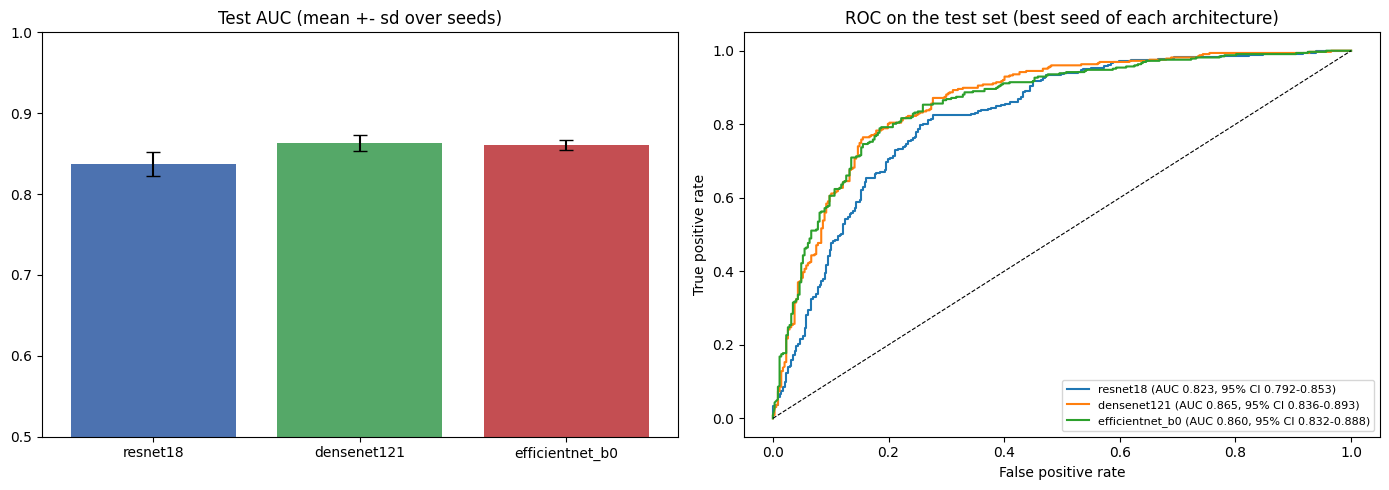

           arch                 run_id  test_auc  ci_low  ci_high
       resnet18        resnet18_s1_e20    0.8228  0.7918   0.8533
    densenet121     densenet121_s0_e20    0.8649  0.8364   0.8933
efficientnet_b0 efficientnet_b0_s2_e20    0.8603  0.8321   0.8878
               variant  val_auc  test_auc  test_ci_low  test_ci_high
    single (best seed)   0.8844    0.8649       0.8364        0.8933
         single + flip   0.8845    0.8681       0.8409        0.8943
       3-seed ensemble   0.8980    0.8771       0.8498        0.9032
3-seed ensemble + flip   0.8981    0.8766       0.8496        0.9026
Classifier used in the hybrid pipeline (highest validation AUC): densenet121 - 3-seed ensemble + flip


In [7]:
metric_cols = ["val_auc", "test_auc", "test_accuracy", "test_precision", "test_recall", "test_specificity", "test_f1"]
agg = runs.groupby("arch")[metric_cols].agg(["mean", "std"]).reindex(ARCHS)
summary = pd.DataFrame({m: [f"{agg[(m, 'mean')][a]:.3f} +- {agg[(m, 'std')][a]:.3f}" for a in ARCHS] for m in metric_cols}, index=ARCHS)
print(summary.to_string())
summary.to_csv(f"{OUT}/cls_summary.csv")

best_arch = runs.groupby("arch")["val_auc"].mean().idxmax()
best_row = runs[runs["arch"] == best_arch].sort_values("val_auc", ascending=False).iloc[0]
best_run = best_row["run_id"]
print(f"\nSelected by mean validation AUC: {best_arch} (best seed run: {best_run}, val AUC {best_row['val_auc']:.4f})")

def bootstrap_auc(y, p, n=1000, seed=0):
    r = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        idx = r.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            out.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(out, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
means = [runs[runs["arch"] == a]["test_auc"].mean() for a in ARCHS]
sds = [runs[runs["arch"] == a]["test_auc"].std() for a in ARCHS]
axes[0].bar(ARCHS, means, yerr=sds, capsize=5, color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("Test AUC (mean +- sd over seeds)")
ci_rows = []
for a in ARCHS:
    r = runs[runs["arch"] == a].sort_values("val_auc", ascending=False).iloc[0]
    z = np.load(f"{OUT}/cls_probs/{r['run_id']}.npz")
    fpr, tpr, _ = roc_curve(z["test_y"], z["test_p"])
    lo, hi = bootstrap_auc(z["test_y"], z["test_p"])
    axes[1].plot(fpr, tpr, label=f"{a} (AUC {r['test_auc']:.3f}, 95% CI {lo:.3f}-{hi:.3f})")
    ci_rows.append(dict(arch=a, run_id=r["run_id"], test_auc=r["test_auc"], ci_low=lo, ci_high=hi))
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_title("ROC on the test set (best seed of each architecture)")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/fig_classifier_comparison.png", dpi=150)
plt.show()
pd.DataFrame(ci_rows).to_csv(f"{OUT}/cls_test_auc_ci.csv", index=False)
print(pd.DataFrame(ci_rows).round(4).to_string(index=False))

# --- 3-seed ensemble and horizontal-flip test-time augmentation of the selected architecture ---
@torch.no_grad()
def predict_probs_ens(models_list, loader, flip=True):
    out = []
    for x, _ in loader:
        x = x.to(device).float()
        acc, n = 0, 0
        for m in models_list:
            m.eval()
            acc = acc + torch.sigmoid(m(x))
            n += 1
            if flip:
                acc = acc + torch.sigmoid(m(torch.flip(x, dims=[3])))
                n += 1
        out.append((acc / n).cpu().numpy().ravel())
    return np.concatenate(out)

ens_models = []
for s in SEEDS:
    m = get_model(best_arch)
    m.load_state_dict(torch.load(f"{OUT}/classifiers/{best_arch}_s{s}_e{EPOCHS}.pt", map_location=device))
    m.eval()
    ens_models.append(m)
best_single = [ens_models[SEEDS.index(int(best_row["seed"]))]]
val_loader_e = DataLoader(SliceDataset(val_tab), batch_size=64, shuffle=False, num_workers=2)
test_loader_e = DataLoader(SliceDataset(test_tab), batch_size=64, shuffle=False, num_workers=2)
yv_e, yt_e = val_tab["label"].values, test_tab["label"].values
variants = {"single (best seed)": (best_single, False), "single + flip": (best_single, True),
            "3-seed ensemble": (ens_models, False), "3-seed ensemble + flip": (ens_models, True)}
ens_rows = []
for name, (mods, fl) in variants.items():
    vp_e, tp_e = predict_probs_ens(mods, val_loader_e, fl), predict_probs_ens(mods, test_loader_e, fl)
    lo, hi = bootstrap_auc(yt_e, tp_e)
    ens_rows.append(dict(variant=name, val_auc=roc_auc_score(yv_e, vp_e), test_auc=roc_auc_score(yt_e, tp_e), test_ci_low=lo, test_ci_high=hi))
ens_df = pd.DataFrame(ens_rows)
print(ens_df.round(4).to_string(index=False))
ens_df.to_csv(f"{OUT}/cls_ensemble.csv", index=False)
CLS_NAME = ens_df.sort_values("val_auc", ascending=False).iloc[0]["variant"]      # chosen on validation AUC only
CLS_MODELS, CLS_FLIP = variants[CLS_NAME]
print("Classifier used in the hybrid pipeline (highest validation AUC):", best_arch, "-", CLS_NAME)

## Step 7: Hybrid pipeline helpers

In [8]:
def iou_xywh(a, b):
    ax1, ay1, ax2, ay2 = a[0] - a[2] / 2, a[1] - a[3] / 2, a[0] + a[2] / 2, a[1] + a[3] / 2
    bx1, by1, bx2, by2 = b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
    iw, ih = max(0.0, min(ax2, bx2) - max(ax1, bx1)), max(0.0, min(ay2, by2) - max(ay1, by1))
    inter = iw * ih
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union if union > 0 else 0.0

def hit_confidence(pred_boxes, pred_conf, gt_boxes, iou_thr=0.5):
    best = 0.0
    for pb, pc in zip(pred_boxes, pred_conf):
        if any(iou_xywh(pb, g) >= iou_thr for g in gt_boxes):
            best = max(best, float(pc))
    return best

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def mode_metrics(mode, y, cls_p, det_max, hit_conf, tc, td):
    y = np.asarray(y).astype(bool)
    if mode == "cls":
        pred = cls_p >= tc
    elif mode == "det":
        pred = det_max >= td
    else:
        pred = (cls_p >= tc) & (det_max >= td)
    if mode in ("and_loc", "and_loc30"):
        tp = int((pred & y & (hit_conf >= td)).sum())
        fp = int(pred.sum()) - tp
        fn = int(y.sum()) - tp
        acc = float("nan")
    else:
        tp, fp, fn = int((pred & y).sum()), int((pred & ~y).sum()), int((~pred & y).sum())
        acc = float((pred == y).mean())
    p, r, f1 = prf(tp, fp, fn)
    return dict(accuracy=acc, precision=p, recall=r, f1=f1, tp=tp, fp=fp, fn=fn)

TC_GRID = np.round(np.arange(0.05, 0.91, 0.05), 2)
TD_GRID = np.array([0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50])

def tune_thresholds(mode, y, cls_p, det_max, hit_conf):
    best, best_f1 = (0.5, 0.25), -1.0
    tcs = TC_GRID if mode in ("cls", "and", "and_loc", "and_loc30") else [0.5]
    tds = TD_GRID if mode in ("det", "and", "and_loc", "and_loc30") else [0.25]
    for tc in tcs:
        for td in tds:
            f1 = mode_metrics(mode, y, cls_p, det_max, hit_conf, tc, td)["f1"]
            if f1 > best_f1:
                best_f1, best = f1, (float(tc), float(td))
    return best, best_f1

## Step 8: Run classifier and detector on validation and test images

In [9]:
from ultralytics import YOLO

det_csv = find_file(f"det_results_{MAIN_SPLIT}.csv")
assert det_csv, f"det_results_{MAIN_SPLIT}.csv not found. Add notebook 02's output as input."
det_tab = pd.read_csv(det_csv).drop_duplicates("run_id", keep="last").sort_values("val_map50", ascending=False)
best_det = det_tab.iloc[0]
det_run = best_det["run_id"]
DET_IMGSZ = int(best_det["imgsz"]) if "imgsz" in det_tab.columns and pd.notna(best_det.get("imgsz")) else IMG_SIZE
DET_PLAIN = str(best_det.get("dataset", "")) == "plain_unbal"
det_path = os.path.join(os.path.dirname(det_csv), "weights", f"{det_run}_best.pt")
assert os.path.exists(det_path), f"weights for {det_run} not found next to {det_csv}"
detector = YOLO(det_path)
print(det_tab[["run_id", "val_map50"]].round(4).to_string(index=False))
print(f"Selected detector (highest validation mAP50): {det_run} | input size {DET_IMGSZ} | plain input: {DET_PLAIN}")
det_tab.to_csv(f"{OUT}/hybrid_detector_candidates.csv", index=False)

DET_MIN_CONF = 0.01      # keep low-confidence boxes so that thresholds down to 0.01 can be tuned on validation

def det_input(gray, code):
    return make_plain_image(gray) if DET_PLAIN else make_modality_image(gray, code)

classifier = get_model(best_arch)
classifier.load_state_dict(torch.load(f"{OUT}/classifiers/{best_run}.pt", map_location=device))
classifier.eval()

def run_pipeline(table, batch=32):
    loader = DataLoader(SliceDataset(table), batch_size=64, shuffle=False, num_workers=2)
    cls_p = predict_probs_ens(CLS_MODELS, loader, CLS_FLIP)
    det_boxes, det_conf = [], []
    for i in range(0, len(table), batch):
        arrays = []
        for _, r in table.iloc[i:i + batch].iterrows():
            gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
            arrays.append(det_input(gray, r["modality_code"]))
        for res in detector.predict(arrays, conf=DET_MIN_CONF, imgsz=DET_IMGSZ, verbose=False):
            det_boxes.append(res.boxes.xywhn.cpu().numpy().tolist())
            det_conf.append(res.boxes.conf.cpu().numpy().tolist())
    det_max = np.array([max(c) if len(c) else 0.0 for c in det_conf])
    hit = np.array([hit_confidence(b, c, g) if len(g) else 0.0
                    for b, c, g in zip(det_boxes, det_conf, table["boxes"])])
    hit30 = np.array([hit_confidence(b, c, g, 0.3) if len(g) else 0.0
                      for b, c, g in zip(det_boxes, det_conf, table["boxes"])])
    out = table[["abs_path", "SeriesInstanceUID", "Modality", "label"]].copy()
    out["cls_p"], out["det_max"], out["hit_conf"], out["hit_conf30"] = cls_p, det_max, hit, hit30
    return out, det_boxes, det_conf

val_res, _, _ = run_pipeline(val_tab)
test_res, test_boxes, test_conf = run_pipeline(test_tab)
test_res.to_csv(f"{OUT}/hybrid_per_image_test.csv", index=False)
print("Done:", len(val_res), "val and", len(test_res), "test images")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
     run_id  val_map50
M4_imgsz448     0.6491
M2_modality     0.5947
 M5_yolo26s     0.5900
M1_baseline     0.5761
 M6_yolo26m     0.5632
M3_balanced     0.5432
Selected detector (highest validation mAP50): M4_imgsz448 | input size 448 | plain input: False
Done: 648 val and 674 test images


## Step 9: Hybrid results (thresholds chosen on validation, applied once to test)

In [10]:
yv, yt = val_res["label"].values, test_res["label"].values
rows, chosen = [], {}
for mode, desc in [("cls", f"A: {best_arch} ({CLS_NAME}) only"), ("det", f"B: {det_run} only (max confidence)"),
                   ("and", "C: classifier AND detector"), ("and_loc", "D: C + box overlaps annotation (IoU>=0.5)"),
                   ("and_loc30", "E: C + box overlaps annotation (IoU>=0.3, looser)")]:
    hcol = "hit_conf30" if mode == "and_loc30" else "hit_conf"
    (tc, td), val_f1 = tune_thresholds(mode, yv, val_res["cls_p"].values, val_res["det_max"].values, val_res[hcol].values)
    m = mode_metrics(mode, yt, test_res["cls_p"].values, test_res["det_max"].values, test_res[hcol].values, tc, td)
    chosen[mode] = (tc, td)
    rows.append(dict(mode=desc, cls_threshold=tc if mode != "det" else None, det_threshold=td if mode != "cls" else None,
                     val_f1=round(val_f1, 3), **{k: round(v, 3) if isinstance(v, float) else v for k, v in m.items()}))
hybrid_df = pd.DataFrame(rows)
print(hybrid_df.to_string(index=False))
hybrid_df.to_csv(f"{OUT}/hybrid_results.csv", index=False)

aucs = dict(classifier_auc=roc_auc_score(yt, test_res["cls_p"]), detector_max_conf_auc=roc_auc_score(yt, test_res["det_max"]),
            product_score_auc=roc_auc_score(yt, test_res["cls_p"] * test_res["det_max"]))
print({k: round(v, 3) for k, v in aucs.items()})

per_mod = []
for mod, g in test_res.groupby("Modality"):
    row = dict(modality=mod, images=len(g), positives=int(g["label"].sum()))
    if g["label"].nunique() == 2:
        row["classifier_auc"] = round(roc_auc_score(g["label"], g["cls_p"]), 3)
    m = mode_metrics("and_loc", g["label"].values, g["cls_p"].values, g["det_max"].values, g["hit_conf"].values, *chosen["and_loc"])
    row.update(and_loc_precision=round(m["precision"], 3), and_loc_recall=round(m["recall"], 3))
    per_mod.append(row)
print(pd.DataFrame(per_mod).to_string(index=False))
pd.DataFrame(per_mod).to_csv(f"{OUT}/hybrid_per_modality.csv", index=False)

                                             mode  cls_threshold  det_threshold  val_f1  accuracy  precision  recall    f1  tp  fp  fn
     A: densenet121 (3-seed ensemble + flip) only           0.45            NaN   0.815     0.804      0.786   0.820 0.802 268  73  59
             B: M4_imgsz448 only (max confidence)            NaN          0.075   0.831     0.823      0.799   0.850 0.824 278  70  49
                       C: classifier AND detector           0.05          0.075   0.825     0.835      0.825   0.838 0.832 274  58  53
        D: C + box overlaps annotation (IoU>=0.5)           0.05          0.010   0.755       NaN      0.668   0.780 0.719 255 127  72
E: C + box overlaps annotation (IoU>=0.3, looser)           0.45          0.020   0.759       NaN      0.746   0.709 0.727 232  79  95
{'classifier_auc': np.float64(0.877), 'detector_max_conf_auc': np.float64(0.89), 'product_score_auc': np.float64(0.897)}
  modality  images  positives  classifier_auc  and_loc_precision  and

## Step 10: Hybrid examples - true positives, false positives and missed cases

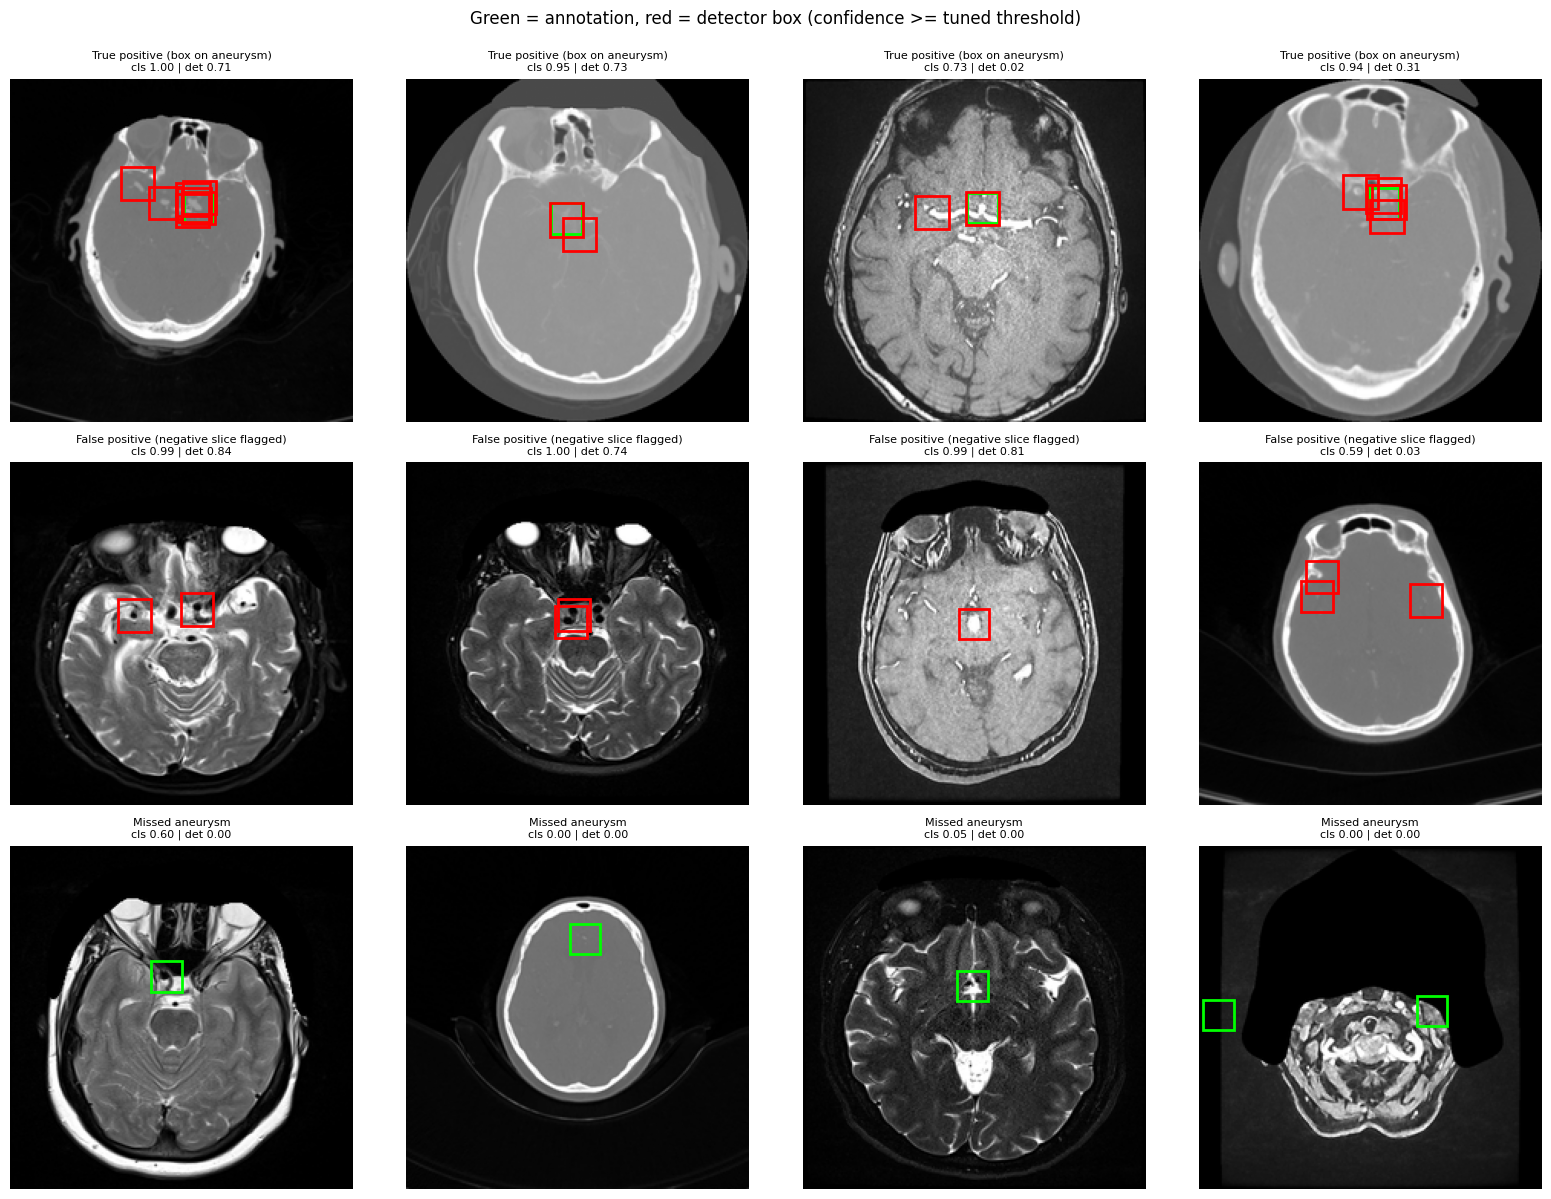

In [11]:
tc, td = chosen["and_loc"]
pred = ((test_res["cls_p"] >= tc) & (test_res["det_max"] >= td)).values
y = yt.astype(bool)
good = pred & y & (test_res["hit_conf"].values >= td)
groups = {"True positive (box on aneurysm)": np.where(good)[0],
          "False positive (negative slice flagged)": np.where(pred & ~y)[0],
          "Missed aneurysm": np.where(~pred & y)[0]}
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
rng_ex = np.random.default_rng(0)
for r_i, (title, idxs) in enumerate(groups.items()):
    chosen_idx = rng_ex.choice(idxs, size=min(4, len(idxs)), replace=False) if len(idxs) else []
    for c_i in range(4):
        ax = axes[r_i, c_i]
        ax.axis("off")
        if c_i >= len(chosen_idx):
            continue
        i = int(chosen_idx[c_i])
        gray = cv2.imread(test_tab.loc[i, "abs_path"], cv2.IMREAD_GRAYSCALE)
        ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
        for b in test_tab.loc[i, "boxes"]:
            ax.add_patch(plt.Rectangle(((b[0] - b[2] / 2) * IMG_SIZE, (b[1] - b[3] / 2) * IMG_SIZE),
                                       b[2] * IMG_SIZE, b[3] * IMG_SIZE, fill=False, edgecolor="lime", lw=2))
        for b, c in zip(test_boxes[i], test_conf[i]):
            if c >= td:
                ax.add_patch(plt.Rectangle(((b[0] - b[2] / 2) * IMG_SIZE, (b[1] - b[3] / 2) * IMG_SIZE),
                                           b[2] * IMG_SIZE, b[3] * IMG_SIZE, fill=False, edgecolor="red", lw=2))
        ax.set_title(f"{title}\ncls {test_res.loc[i, 'cls_p']:.2f} | det {test_res.loc[i, 'det_max']:.2f}", fontsize=8)
plt.suptitle("Green = annotation, red = detector box (confidence >= tuned threshold)", y=0.995)
plt.tight_layout()
plt.savefig(f"{OUT}/fig_hybrid_examples.png", dpi=150)
plt.show()

## Step 11: Explainability helpers

In [12]:
from scipy.stats import wilcoxon

def box_mask(boxes, pad=0.03, size=IMG_SIZE):
    m = np.zeros((size, size), dtype=bool)
    for x, y, w, h in boxes:
        x1, x2 = int(max(0, (x - w / 2 - pad) * size)), int(min(size, (x + w / 2 + pad) * size) + 1)
        y1, y2 = int(max(0, (y - h / 2 - pad) * size)), int(min(size, (y + h / 2 + pad) * size) + 1)
        m[y1:y2, x1:x2] = True
    return m

def mass_in_mask(heat, mask):
    s = heat.sum()
    return float(heat[mask].sum() / s) if s > 0 else 0.0

def show_stats(d):
    return pd.Series({k: (round(v, 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}).to_string()

def quantify_heatmaps(name, heats, boxes_list):
    masks = [box_mask(b) for b in boxes_list]
    mass = np.array([mass_in_mask(h, m) for h, m in zip(heats, masks)])
    chance = np.array([m.mean() for m in masks])
    prior = np.mean(np.stack(heats), axis=0)
    prior_mass = np.array([mass_in_mask(prior, m) for m in masks])
    peak_hit = np.array([bool(m[np.unravel_index(np.argmax(h), h.shape)]) for h, m in zip(heats, masks)])
    def p(a, b):
        return float(wilcoxon(a, b, alternative="greater").pvalue) if np.any(a != b) else 1.0
    return dict(method=name, n_images=len(heats), mean_mass_in_box=mass.mean(), mean_chance=chance.mean(),
                mass_over_chance=mass.mean() / chance.mean(), pct_images_above_chance=float((mass > chance).mean()),
                p_vs_chance=p(mass, chance), mean_mass_position_prior=prior_mass.mean(),
                pct_images_above_prior=float((mass > prior_mass).mean()), p_vs_prior=p(mass, prior_mass),
                peak_in_box_rate=peak_hit.mean(), peak_in_box_expected=chance.mean())

## Step 12: Grad-CAM for the classifier (class = aneurysm), quantified

method                      Grad-CAM (classifier)
n_images                                      327
mean_mass_in_box                           0.0658
mean_chance                                0.0238
mass_over_chance                           2.7654
pct_images_above_chance                    0.8379
p_vs_chance                                   0.0
mean_mass_position_prior                   0.0659
pct_images_above_prior                     0.6422
p_vs_prior                                 0.0072
peak_in_box_rate                           0.3242
peak_in_box_expected                       0.0238


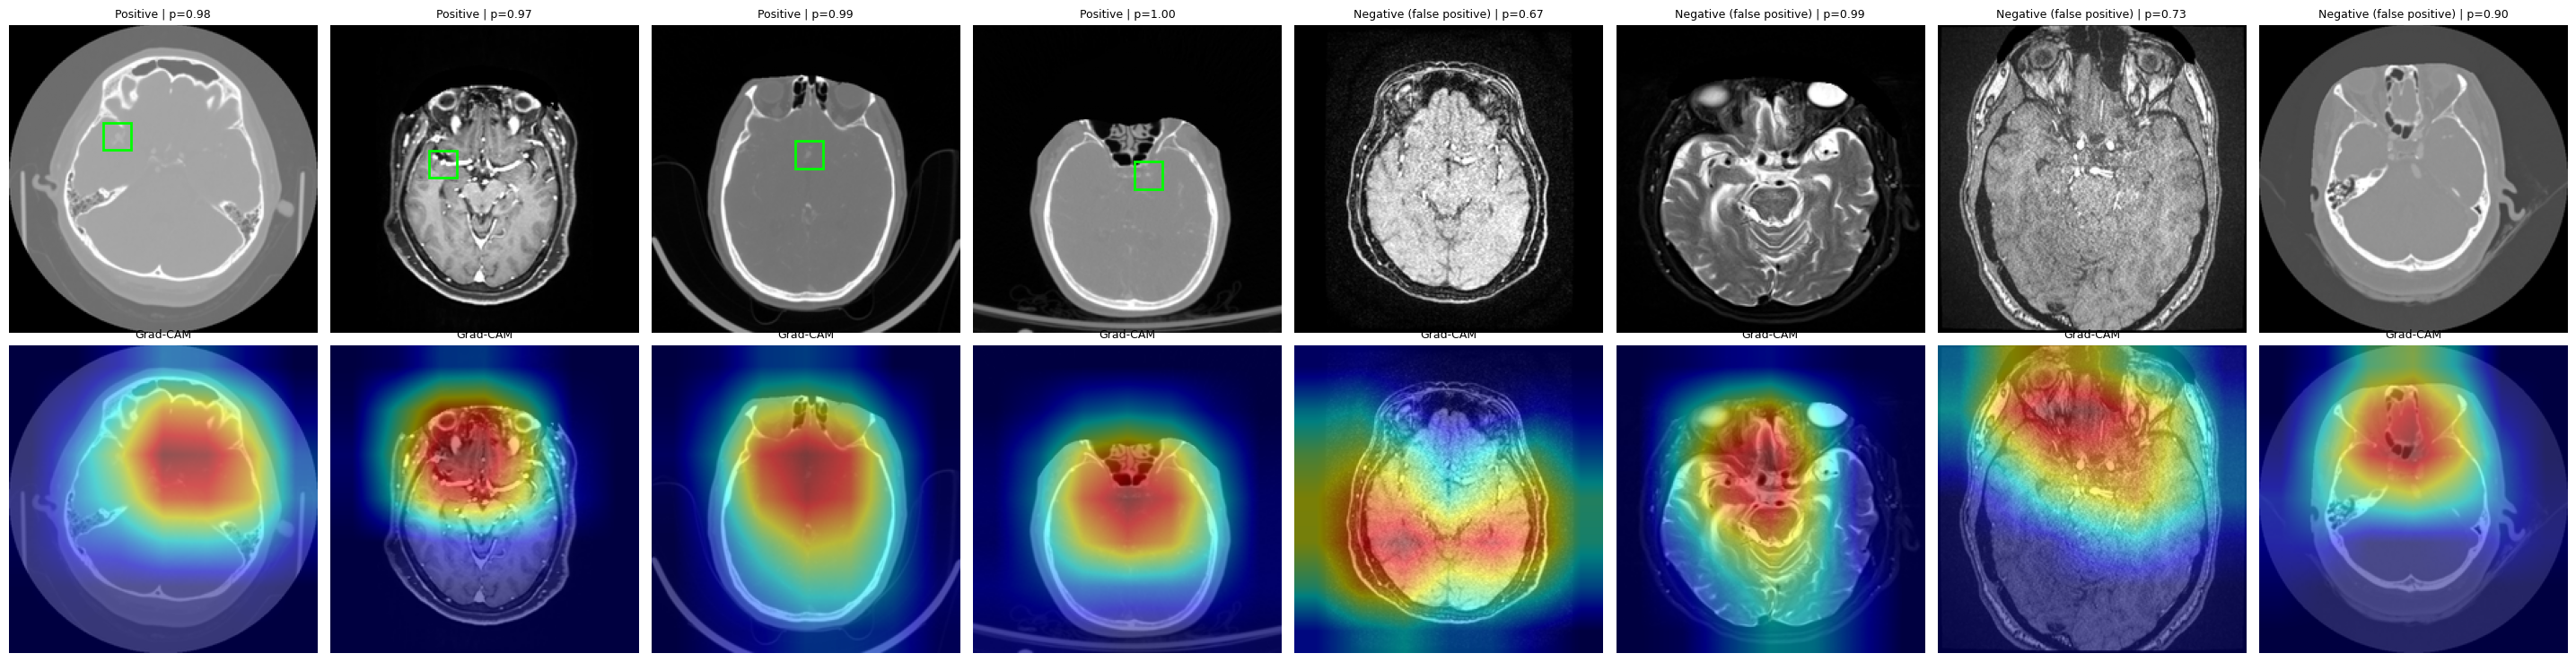

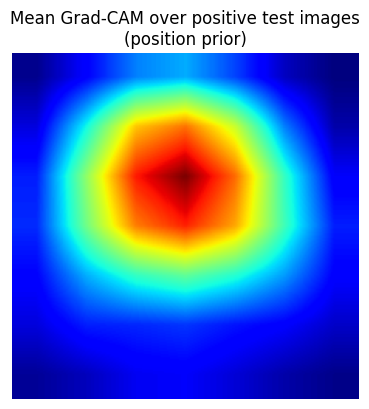

In [13]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import BinaryClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

cam = GradCAM(model=classifier, target_layers=target_layer(classifier, best_arch))

def gradcam_for(table_rows):
    heats = []
    for _, r in table_rows.iterrows():
        gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
        x = to_tensor(make_modality_image(gray, r["modality_code"])).unsqueeze(0).to(device).float()
        heats.append(cam(input_tensor=x, targets=[BinaryClassifierOutputTarget(1)])[0])
    return heats

pos_idx = np.where(yt == 1)[0]
pos_rows = test_tab.iloc[pos_idx]
cam_heats = gradcam_for(pos_rows)
gc_stats = quantify_heatmaps("Grad-CAM (classifier)", cam_heats, pos_rows["boxes"].tolist())
print(show_stats(gc_stats))

fp_idx = np.where(pred & ~y)[0][:4]
show_idx = list(rng_ex.choice(pos_idx, 4, replace=False)) + list(fp_idx)
fig, axes = plt.subplots(2, len(show_idx), figsize=(3.6 * len(show_idx), 7.4))
for c_i, i in enumerate(show_idx):
    r = test_tab.iloc[i]
    gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
    heat = gradcam_for(test_tab.iloc[[i]])[0]
    base = np.stack([gray] * 3, axis=-1).astype(np.float32) / 255.0
    axes[0, c_i].imshow(gray, cmap="gray")
    for b in r["boxes"]:
        axes[0, c_i].add_patch(plt.Rectangle(((b[0] - b[2] / 2) * IMG_SIZE, (b[1] - b[3] / 2) * IMG_SIZE),
                                             b[2] * IMG_SIZE, b[3] * IMG_SIZE, fill=False, edgecolor="lime", lw=2))
    axes[0, c_i].set_title(("Positive" if r["label"] else "Negative (false positive)") + f" | p={test_res.loc[i, 'cls_p']:.2f}", fontsize=9)
    axes[1, c_i].imshow(show_cam_on_image(base, heat, use_rgb=True))
    axes[1, c_i].set_title("Grad-CAM", fontsize=9)
    axes[0, c_i].axis("off")
    axes[1, c_i].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/fig_gradcam.png", dpi=150)
plt.show()

mean_heat = np.mean(np.stack(cam_heats), axis=0)
plt.figure(figsize=(4.5, 4.5))
plt.imshow(mean_heat, cmap="jet")
plt.title("Mean Grad-CAM over positive test images\n(position prior)")
plt.axis("off")
plt.savefig(f"{OUT}/fig_gradcam_mean_map.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 13: Occlusion maps for the detector

Images analysed: 60
method                      Occlusion (detector)
n_images                                      60
mean_mass_in_box                          0.4233
mean_chance                               0.0235
mass_over_chance                         17.9919
pct_images_above_chance                   0.9833
p_vs_chance                                  0.0
mean_mass_position_prior                  0.1826
pct_images_above_prior                      0.85
p_vs_prior                                   0.0
peak_in_box_rate                          0.8667
peak_in_box_expected                      0.0235


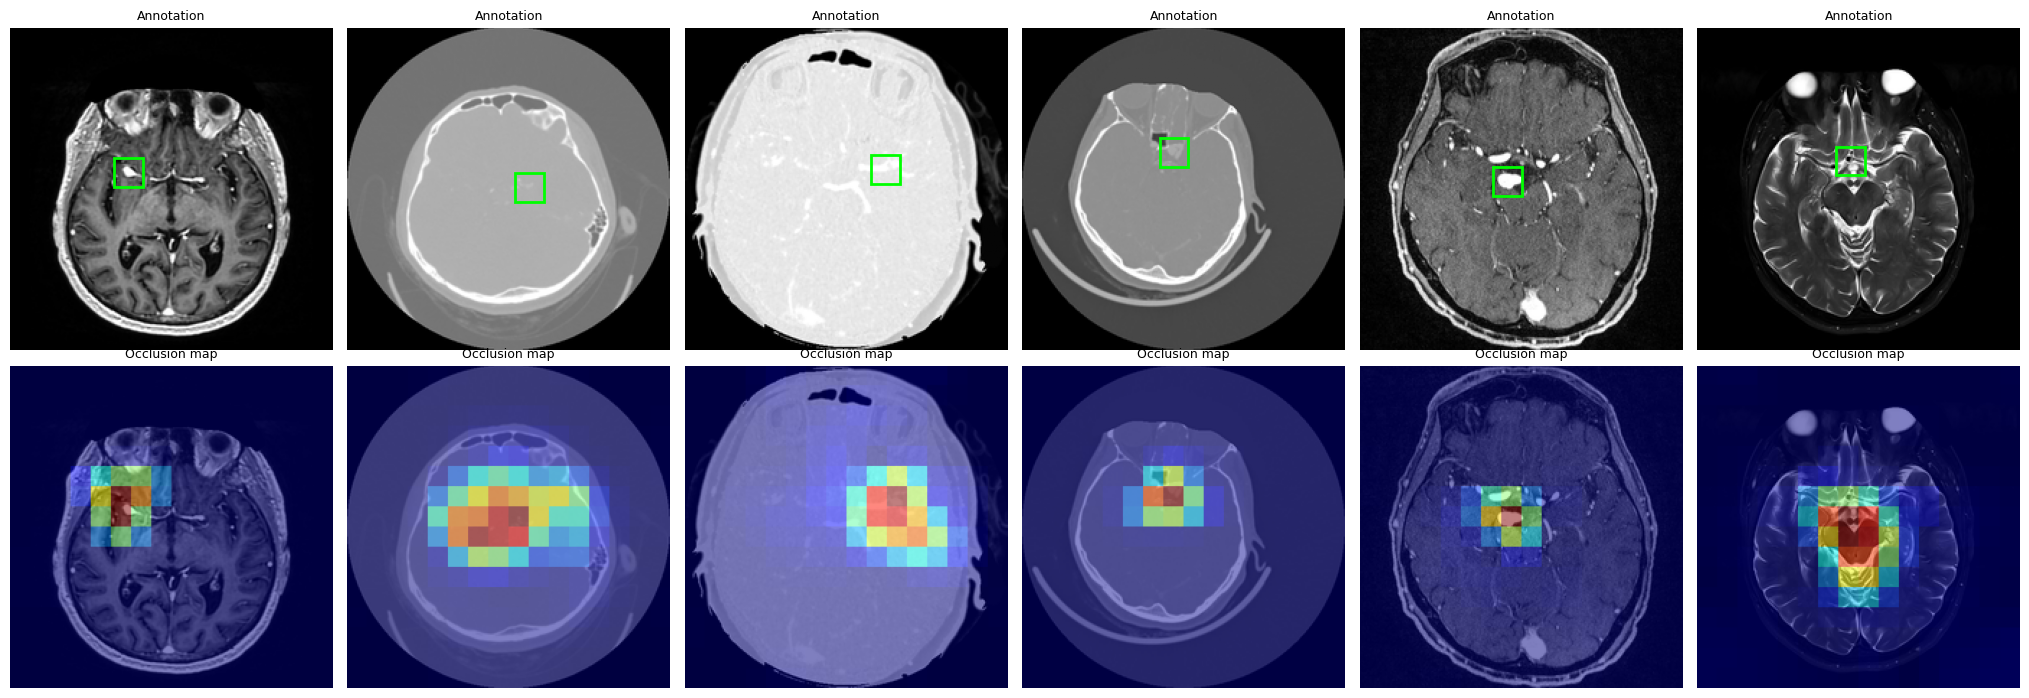

In [14]:
PATCH, STRIDE = 28, 14

def det_score(arrays, mask):
    out = []
    for res in detector.predict(arrays, conf=0.01, imgsz=DET_IMGSZ, verbose=False):
        s = 0.0
        for b, c in zip(res.boxes.xywhn.cpu().numpy(), res.boxes.conf.cpu().numpy()):
            cx, cy = int(min(max(b[0] * IMG_SIZE, 0), IMG_SIZE - 1)), int(min(max(b[1] * IMG_SIZE, 0), IMG_SIZE - 1))
            if mask[cy, cx]:
                s = max(s, float(c))
        out.append(s)
    return np.array(out)

def occlusion_map(gray, code, boxes):
    mask = box_mask(boxes, pad=0.05)
    base = det_input(gray, code)
    s0 = det_score([base], mask)[0]
    if s0 < 0.25:
        return None, s0
    fill = int(gray.mean())
    arrays, pos = [], []
    for y0 in range(0, IMG_SIZE - PATCH + 1, STRIDE):
        for x0 in range(0, IMG_SIZE - PATCH + 1, STRIDE):
            a = base.copy()
            a[y0:y0 + PATCH, x0:x0 + PATCH, :(3 if DET_PLAIN else 2)] = fill
            arrays.append(a)
            pos.append((y0, x0))
    scores = np.concatenate([det_score(arrays[i:i + 64], mask) for i in range(0, len(arrays), 64)])
    heat, cnt = np.zeros((IMG_SIZE, IMG_SIZE)), np.zeros((IMG_SIZE, IMG_SIZE))
    for (y0, x0), s in zip(pos, scores):
        heat[y0:y0 + PATCH, x0:x0 + PATCH] += max(0.0, s0 - s)
        cnt[y0:y0 + PATCH, x0:x0 + PATCH] += 1
    return heat / np.maximum(cnt, 1), s0

OCC_MAX = 60
occ_heats, occ_boxes, occ_idx = [], [], []
for i in np.random.default_rng(1).permutation(pos_idx):
    i = int(i)
    if len(occ_heats) >= OCC_MAX:
        break
    r = test_tab.iloc[i]
    gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
    heat, s0 = occlusion_map(gray, r["modality_code"], r["boxes"])
    if heat is not None and heat.sum() > 0:
        occ_heats.append(heat)
        occ_boxes.append(r["boxes"])
        occ_idx.append(i)
print("Images analysed:", len(occ_heats))
occ_stats = quantify_heatmaps("Occlusion (detector)", occ_heats, occ_boxes) if len(occ_heats) >= 5 else None
if occ_stats:
    print(show_stats(occ_stats))

n_show = min(6, len(occ_idx))
if n_show:
    fig, axes = plt.subplots(2, n_show, figsize=(3.4 * n_show, 7), squeeze=False)
    for c_i in range(n_show):
        r = test_tab.iloc[occ_idx[c_i]]
        gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
        axes[0, c_i].imshow(gray, cmap="gray")
        for b in r["boxes"]:
            axes[0, c_i].add_patch(plt.Rectangle(((b[0] - b[2] / 2) * IMG_SIZE, (b[1] - b[3] / 2) * IMG_SIZE),
                                                 b[2] * IMG_SIZE, b[3] * IMG_SIZE, fill=False, edgecolor="lime", lw=2))
        axes[0, c_i].set_title("Annotation", fontsize=9)
        h = occ_heats[c_i] / max(occ_heats[c_i].max(), 1e-9)
        axes[1, c_i].imshow(show_cam_on_image(np.stack([gray] * 3, axis=-1).astype(np.float32) / 255.0, h, use_rgb=True))
        axes[1, c_i].set_title("Occlusion map", fontsize=9)
        axes[0, c_i].axis("off")
        axes[1, c_i].axis("off")
    plt.tight_layout()
    plt.savefig(f"{OUT}/fig_occlusion.png", dpi=150)
    plt.show()

## Step 14: Summary

In [15]:
xai_df = pd.DataFrame([s for s in [gc_stats, occ_stats] if s])
xai_df.to_csv(f"{OUT}/xai_quantification.csv", index=False)
print(xai_df.round(4).T.to_string())

summary_json = dict(
    selected_classifier=best_arch, selected_run=best_run, selected_detector=det_run,
    mean_val_auc={a: float(runs[runs['arch'] == a]['val_auc'].mean()) for a in ARCHS},
    mean_test_auc={a: float(runs[runs['arch'] == a]['test_auc'].mean()) for a in ARCHS},
    hybrid=hybrid_df.to_dict(orient="records"), auc=aucs,
)
json.dump(summary_json, open(f"{OUT}/notebook04_summary.json", "w"), indent=2, default=float)
print(json.dumps({k: summary_json[k] for k in ["selected_classifier", "mean_test_auc", "auc"]}, indent=2, default=float))

                                              0                     1
method                    Grad-CAM (classifier)  Occlusion (detector)
n_images                                    327                    60
mean_mass_in_box                         0.0658                0.4233
mean_chance                              0.0238                0.0235
mass_over_chance                         2.7654               17.9919
pct_images_above_chance                  0.8379                0.9833
p_vs_chance                                 0.0                   0.0
mean_mass_position_prior                 0.0659                0.1826
pct_images_above_prior                   0.6422                  0.85
p_vs_prior                               0.0072                   0.0
peak_in_box_rate                         0.3242                0.8667
peak_in_box_expected                     0.0238                0.0235
{
  "selected_classifier": "densenet121",
  "mean_test_auc": {
    "resnet18": 0.836866666